# Climate-model grid resolution

Horizontal-resolution formulas followed by climate-model comparisons across IPCC assessment reports.

Run the notebook from top to bottom. Local section numbers are retained within each part.

1. [12c: IPCC Grid-Resolution Formulas](#part-12c)
2. [12d: IPCC Assessment-Report Model Grids](#part-12d)


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import integrate

<a id="part-12c"></a>

## Part 1 — 12c: IPCC Grid-Resolution Formulas

A global grid-box-count estimate, followed by the derivation,
visualization, integration, and tabulation of the IPCC-style
horizontal-resolution formula

$$R(\varphi) = \ell_\varphi \sqrt{\Delta\varphi\cdot\Delta\lambda\cdot\cos\varphi},
\qquad \ell_\varphi = \frac{\pi R_{\oplus}}{180}$$

— the physical ground distance (km) spanned by a $\Delta\varphi\times
\Delta\lambda$ degree grid cell at latitude $\varphi$, which shrinks
toward the poles as meridians converge ($\cos\varphi\to0$). The final
section introduces a shared `compute_horizontal_resolution` helper that a
later notebook (`12d`) reuses directly.


In [2]:
DATA_DIR = "../../data"

color_blue = "#1f77b4"

plt.rcParams["figure.dpi"] = 100

### 1. Global grid-box-count estimate

A back-of-the-envelope estimate of how many grid boxes (and how much data)
a climate model produces: Earth's surface area divided into $100\times100$
km boxes, inflated by a factor of $L=10$ (vertical levels), fixed at a
round $510{,}000$ boxes times $7$ variables, times $24$ hourly time steps
per day, times $100$ years of daily data.


In [3]:
R = 6371.0  # km
A = 4 * np.pi * R**2
print(f"A = {A:,.0f} km^2")

h = 100.0
n_boxes = A / (h * h)
print(f"# boxes = {n_boxes:,.0f}")

L = 10
n_boxes = L * n_boxes
print(f"# boxes = {n_boxes:,.0f}")

n_boxes = 510_000
n_var = 7
n_boxes = n_var * n_boxes
print(f"# boxes = {n_boxes:,.0f}")

dt = 24
n_boxes = dt * n_boxes
print(f"# boxes / day = {n_boxes:,.0f}")

n_year = 100
n_boxes = n_year * 365 * n_boxes
print(f"# boxes / 100 years = {n_boxes:,.0f}")

A = 510,064,472 km^2
# boxes = 51,006
# boxes = 510,064
# boxes = 3,570,000
# boxes / day = 85,680,000
# boxes / 100 years = 3,127,320,000,000


### 2. The resolution formula, evaluated pointwise

$\ell_\varphi$ for the WGS84 semi-major/semi-minor axes and for the mean
Earth radius $R=6371$ km, then the shrinking east-west distance
$\ell_\varphi\cos\varphi$ and the full resolution formula $R(\varphi)$
(for $\Delta\varphi=\Delta\lambda=10°$) at five representative
latitudes.


In [4]:
R_axes = np.array([6378.137, 6356.752])
length_phi_axes = np.pi * R_axes / 180
print("length_phi (WGS84 a, b):", np.round(length_phi_axes, 2))

R = 6371.0
length_phi = np.pi * R / 180
print(f"length_phi (R=6371 km) = {length_phi:.1f} km/deg")

phi_deg = np.array([0, 30, 45, 60, 90])
phi = np.radians(phi_deg)
length_delta = length_phi * np.cos(phi)
display(
    pd.Series(
        np.round(length_delta, 1),
        index=[f"{d}\u00b0" for d in phi_deg],
        name="length_phi*cos(phi) (km)",
    )
)

delta_phi = delta_lambda = 10.0
R_res = length_phi * np.sqrt(delta_phi * delta_lambda * np.cos(phi))
display(
    pd.Series(
        np.round(R_res, 0),
        index=[f"{d}\u00b0" for d in phi_deg],
        name="R(phi), 10x10 deg grid (km)",
    )
)

length_phi (WGS84 a, b): [111.32 110.95]
length_phi (R=6371 km) = 111.2 km/deg


0°     111.2
30°     96.3
45°     78.6
60°     55.6
90°      0.0
Name: length_phi*cos(phi) (km), dtype: float64

0°     1112.0
30°    1035.0
45°     935.0
60°     786.0
90°       0.0
Name: R(phi), 10x10 deg grid (km), dtype: float64

### 3. Resolution vs. latitude, continuously

The same $10°\times10°$-grid resolution formula plotted continuously from
the equator to the pole, with extra density near $90°$ where the curve's
behavior changes fastest.


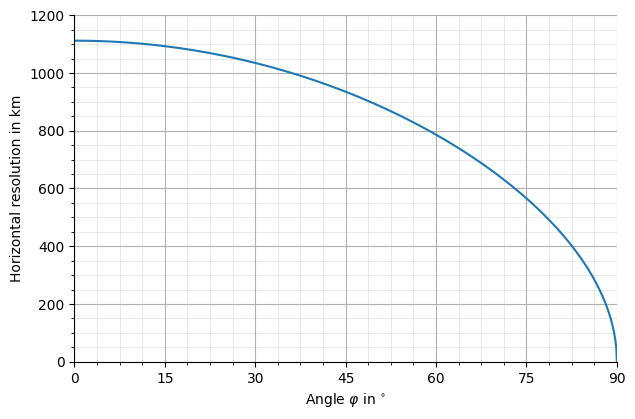

In [5]:
length_phi = np.pi * R / 180
phi_deg = np.concatenate([np.arange(0, 0.9 * 90, 0.2), np.arange(0.9 * 90, 90 + 0.1, 0.1)])
phi = np.radians(phi_deg)
delta_phi = delta_lambda = 10.0
R_curve = length_phi * np.sqrt(delta_phi * delta_lambda * np.cos(phi))

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(phi_deg, R_curve, "-", color=color_blue, linewidth=1.5)
ax.grid(True, which="major")
ax.grid(True, which="minor", linewidth=0.4, alpha=0.5)
ax.minorticks_on()
ax.set_xlabel(r"Angle $\varphi$ in $^{\circ}$")
ax.set_ylabel("Horizontal resolution in km")
ax.set_xlim(0, 90)
ax.set_xticks(range(0, 91, 15))
ax.set_ylim(0, 1200)
ax.set_yticks(range(0, 1201, 200))
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.show()

### 4. Latitude-averaged resolution, by integration

The mean value of $\sqrt{\cos\varphi}$ (dimensionless), and of the full
resolution formula at $\Delta\varphi=1°$, $10°$, and $1.1°$, each averaged
over $\varphi\in[0,\pi/2]$ via $\frac{1}{\pi/2}\int_0^{\pi/2}(\cdot)\,d\varphi$.


In [6]:
length_phi = np.pi * R / 180
delta_phi = delta_lambda = 1.0
int1 = integrate.quad(lambda phi: np.sqrt(delta_phi * delta_lambda * np.cos(phi)), 0, np.pi / 2)[
    0
] / (np.pi / 2)
int2 = integrate.quad(
    lambda phi: length_phi * np.sqrt(delta_phi * delta_lambda * np.cos(phi)), 0, np.pi / 2
)[0] / (np.pi / 2)

delta_phi = delta_lambda = 10.0
int3 = integrate.quad(
    lambda phi: length_phi * np.sqrt(delta_phi * delta_lambda * np.cos(phi)), 0, np.pi / 2
)[0] / (np.pi / 2)

print(f"[int1, int2, int3] = [{int1:.4f}, {int2:.4f}, {int3:.4f}]")

delta_phi = delta_lambda = 1.1
int4 = integrate.quad(
    lambda phi: length_phi * np.sqrt(delta_phi * delta_lambda * np.cos(phi)), 0, np.pi / 2
)[0] / (np.pi / 2)
print(f"int4 = {int4:.4f}")

[int1, int2, int3] = [0.7628, 84.8150, 848.1502]
int4 = 93.2965


### 5. Resolution table across grid sizes

$R(\varphi)$ at the equator and at $45°$, plus the average-resolution
shortcut $R_{avg}=0.7628\,\ell_\varphi\,\Delta\varphi$ (the $\sqrt{\cos}$
factor's own latitude-average from the previous section's
$\Delta\varphi=1°$ integral, folded into a single constant), for a
descending sequence of grid resolutions typical of climate-model
generations (a coarse $5.6°$ FAR-era grid down to a fine $0.375°$ AR6-era
grid).


In [7]:
length_phi = np.pi * R / 180
print(f"length_phi = {length_phi:.1f} km/deg")

phi_deg = np.array([0, 45])
phi = np.radians(phi_deg)
delta_phi = np.array([5.6, 4.0, 2.8, 2.5, 1.9, 1.4, 1.1, 0.75, 0.375])
delta_lambda = delta_phi

R_table = length_phi * np.sqrt(np.outer(delta_phi * delta_lambda, np.ones_like(phi)) * np.cos(phi))
R_avg = 0.7628 * length_phi * np.sqrt(delta_phi * delta_lambda)

result = pd.DataFrame(R_table, index=delta_phi, columns=[f"R(phi={d}deg)" for d in phi_deg])
result["R_avg"] = R_avg
result.index.name = "delta_phi=delta_lambda (deg)"
display(result.round(0))

length_phi = 111.2 km/deg


,R(phi=0deg),R(phi=45deg),R_avg
delta_phi=delta_lambda (deg),,,
5.600,623.0,524.0,475.0
4.000,445.0,374.0,339.0
2.800,311.0,262.0,237.0
2.500,278.0,234.0,212.0
1.900,211.0,178.0,161.0
1.400,156.0,131.0,119.0
1.100,122.0,103.0,93.0
0.750,83.0,70.0,64.0
0.375,42.0,35.0,32.0


### 6. Same table via a shared resolution helper

Repeats the previous section's table (with a $10°$ resolution added at the
coarse end) through a shared `compute_horizontal_resolution` helper, which
hardcodes $\ell_\varphi=111.2$ km/deg (i.e. $R=6371$ km, matching this
notebook's value to 1 decimal place) and evaluates $R_0=R(\varphi{=}0)$,
$R_{45}=R(\varphi{=}45°)$, and $R_{avg}=0.7628\,R_0$ directly.


In [8]:
from quanttoolbox.sustainable_finance.physical_risk import compute_horizontal_resolution

# Thin re-export: this notebook's own compute_horizontal_resolution formula now
# lives in quanttoolbox.sustainable_finance.physical_risk (verified numerically
# identical on this notebook's own delta_phi=delta_lambda grid). Returns a
# HorizontalResolutionResult dataclass (r_0, r_45, r_avg) rather than a bare
# tuple, so the call site below uses .r_0/.r_45/.r_avg.


delta_phi = np.array([10, 5.6, 4.0, 2.8, 2.5, 1.9, 1.4, 1.1, 0.75, 0.375])
delta_lambda = delta_phi

res = compute_horizontal_resolution(delta_phi, delta_lambda)
R_0, R_45, R_avg = res.r_0, res.r_45, res.r_avg
result2 = pd.DataFrame(
    {"R_0 (phi=0)": R_0, "R_45 (phi=45deg)": R_45, "R_avg": R_avg}, index=delta_phi
)
result2.index.name = "delta_phi=delta_lambda (deg)"
display(result2.round(0))

,R_0 (phi=0),R_45 (phi=45deg),R_avg
delta_phi=delta_lambda (deg),,,
10.000,1112.0,935.0,848.0
5.600,623.0,524.0,475.0
4.000,445.0,374.0,339.0
2.800,311.0,262.0,238.0
2.500,278.0,234.0,212.0
1.900,211.0,178.0,161.0
1.400,156.0,131.0,119.0
1.100,122.0,103.0,93.0
0.750,83.0,70.0,64.0


<a id="part-12d"></a>

## Part 2 — 12d: IPCC Assessment-Report Model Grids

Summary statistics of climate-model grid resolution and vertical-level
counts, broken down by IPCC Assessment Report generation — FAR (1990)
through AR6 (2021), plus a hypothetical future "AR7" used illustratively.
The first four reports each analyze one assessment report's per-model grid
table (`chap12_ipcc_grid.xlsx`) and share near-identical structure, so
they're collapsed into a single parametrized loop here rather than four
repeated code blocks. The level-count and resolution summaries that follow
select one of several hardcoded literal arrays by assessment-report
number, using a plain Python dict keyed by AR number.


### Shared helpers

`resolution_to_angular` handles three different grid-resolution
conventions used across model generations — rhomboidal spectral
truncation (`"R15"`, `"R21"`, `"R30"`), triangular spectral truncation
(`"T21"` ... `"T319"`), or a plain angular degree string
(`"4°x5°"`, `"2.5°x3.75°"`) — converting each to a
$(\Delta\varphi,\Delta\lambda)$ angle pair before the horizontal-resolution
formula (introduced in the previous notebook) can be applied.
`compute_stats` reports sample size (including any `NaN`s), then
median/min/max/mean of the non-`NaN` values.


In [9]:
from quanttoolbox.sustainable_finance.physical_risk import resolution_to_angular

# Thin re-export: this notebook's own three-notation (rhomboidal/triangular
# spectral/plain angular-degree) resolution-label parser now lives in
# quanttoolbox.sustainable_finance.physical_risk (verified numerically
# identical across all three notations, both against this notebook's own
# lookup tables and every distinct resolution label actually present in
# chap12_ipcc_grid.xlsx). Returns an AngularResolution dataclass
# (delta_phi, delta_lambda) rather than a bare tuple, so call sites below
# use .delta_phi/.delta_lambda.


def compute_horizontal_resolution_angle(delta_phi, delta_lambda):
    # Same formula as the shared compute_horizontal_resolution helper (12c), taking angles directly.
    length_phi = 111.2
    R_0 = length_phi * np.sqrt(delta_phi * delta_lambda * np.cos(0.0))
    R_45 = length_phi * np.sqrt(delta_phi * delta_lambda * np.cos(np.pi / 4))
    R_avg = 0.7628 * R_0
    return R_0, R_45, R_avg


def compute_stats(x):
    # n is the original array length (including any NaNs); median/min/max/mean
    # use numpy's NaN-aware reductions directly -- equivalent to the original
    # drop-NaN-then-reduce logic, with no custom NaN-handling code needed.
    x = np.asarray(x, dtype=float)
    return [len(x), np.nanmedian(x), np.nanmin(x), np.nanmax(x), np.nanmean(x)]


STATS_COLS = ["n", "median", "min", "max", "mean"]

### 1-4. Per-assessment-report grid-resolution and level-count summaries

For each of FAR, SAR, TAR, and AR4: the atmosphere-model grid resolution
$R_0$ (equator), $R_{45}$ (45°), $R_{avg}$ (the `0.7628` shortcut
introduced in the previous notebook), and $R_{typical}=\sqrt{R_0\cdot R_{45}}$,
each summarized across all models in the table, followed by the
vertical-level-count summary (`A_Level` atmosphere, `O_Level` ocean where
available). FAR's table has no ocean-grid-resolution column
(`O_Resolution` is all missing — ocean components weren't consistently
gridded/reported this early), so only FAR skips the ocean-resolution block
that SAR/TAR/AR4 all have.


In [10]:
def analyze_ar_sheet(sheet, has_ocean):
    T = pd.read_excel(f"{DATA_DIR}/chap12_ipcc_grid.xlsx", sheet_name=sheet)
    _A_res = T["A_Resolution"].map(resolution_to_angular)
    T["A_angle_phi"] = _A_res.map(lambda r: r.delta_phi)
    T["A_angle_lambda"] = _A_res.map(lambda r: r.delta_lambda)

    def resolution_stats_block(delta_phi, delta_lambda):
        R_0, R_45, R_avg = compute_horizontal_resolution_angle(
            delta_phi.values, delta_lambda.values
        )
        R_typical = np.sqrt(R_0 * R_45)
        rows = {
            "R_0 (phi=0)": compute_stats(R_0),
            "R_45 (phi=45deg)": compute_stats(R_45),
            "R_avg": compute_stats(R_avg),
            "R_typical": compute_stats(R_typical),
        }
        return pd.DataFrame(rows, index=STATS_COLS).T

    print(f"=== {sheet}: atmosphere grid resolution (km) ===")
    display(resolution_stats_block(T["A_angle_phi"], T["A_angle_lambda"]).round(0))

    print(f"=== {sheet}: vertical-level counts ===")
    level_rows = {"A_Level (atmosphere)": compute_stats(T["A_Level"])}
    if has_ocean:
        level_rows["O_Level (ocean)"] = compute_stats(T["O_Level"])
    display(pd.DataFrame(level_rows, index=STATS_COLS).T.round(1))

    if has_ocean:
        _O_res = T["O_Resolution"].map(resolution_to_angular)
        T["O_angle_phi"] = _O_res.map(lambda r: r.delta_phi)
        T["O_angle_lambda"] = _O_res.map(lambda r: r.delta_lambda)
        print(f"=== {sheet}: ocean grid resolution (km) ===")
        display(resolution_stats_block(T["O_angle_phi"], T["O_angle_lambda"]).round(0))
    print()


for sheet, has_ocean in [("FAR", False), ("SAR", True), ("TAR", True), ("AR4", True)]:
    analyze_ar_sheet(sheet, has_ocean)

=== FAR: atmosphere grid resolution (km) ===


,n,median,min,max,mean
R_0 (phi=0),26.0,646.0,323.0,995.0,634.0
R_45 (phi=45deg),26.0,543.0,272.0,836.0,533.0
R_avg,26.0,493.0,246.0,759.0,483.0
R_typical,26.0,592.0,296.0,912.0,581.0


=== FAR: vertical-level counts ===


,n,median,min,max,mean
A_Level (atmosphere),26.0,9.0,2.0,19.0,9.3



=== SAR: atmosphere grid resolution (km) ===


...

,n,median,min,max,mean
R_0 (phi=0),23.0,278.0,122.0,497.0,293.0
R_45 (phi=45deg),23.0,234.0,103.0,418.0,247.0
R_avg,23.0,212.0,93.0,379.0,224.0
R_typical,23.0,255.0,112.0,456.0,269.0


=== AR4: vertical-level counts ===


,n,median,min,max,mean
A_Level (atmosphere),23.0,24.0,12.0,56.0,26.2
O_Level (ocean),23.0,31.0,13.0,47.0,29.7


=== AR4: ocean grid resolution (km) ===


,n,median,min,max,mean
R_0 (phi=0),23.0,139.0,27.0,497.0,175.0
R_45 (phi=45deg),23.0,117.0,23.0,418.0,147.0
R_avg,23.0,106.0,21.0,379.0,134.0
R_typical,23.0,127.0,25.0,456.0,161.0


### 5. Vertical-level counts across all 7 report generations

Extends the FAR-AR4 level-count summaries above with hardcoded per-model
level-count literals for all 7 assessment-report generations (FAR=AR1
through AR6, plus an illustrative future "AR7"), separately for
atmosphere (AGCM) and ocean (OGCM) components. The FAR/SAR/TAR/AR4
literals here reproduce the same `A_Level`/`O_Level` columns used above
(confirmed matching on manual inspection) — AR5/AR6/AR7 have no grid table
in `chap12_ipcc_grid.xlsx` at all, so these literals are the only source
for them.

Selecting one of the 7 array pairs by assessment-report number uses a
plain Python dict keyed by AR number.


In [11]:
L_LEVELS = {
    1: (
        [9, 9, 2, 2, 5, 9, 9, 9, 4, 7, 9, 9, 9, 9, 11, 11, 11, 11, 11, 10, 9, 11, 9, 9, 19, 19],
        [12, 4, 11, 9],
    ),
    2: (
        [9, 10, 31, 9, 9, 14, 9, 9, 2, 15, 19, 19, 15, 9, 9, 19],
        [12, 29, 20, 16, 12, 18, 13, 16, 20, 20, 11, 9, 21, 20, 15, 20],
    ),
    3: (
        [
            30,
            19,
            9,
            17,
            20,
            10,
            10,
            9,
            18,
            9,
            18,
            18,
            19,
            19,
            19,
            9,
            9,
            14,
            9,
            9,
            9,
            19,
            19,
            15,
            15,
            15,
            30,
            9,
            18,
            18,
            20,
        ],
        [
            31,
            31,
            12,
            12,
            17,
            29,
            29,
            20,
            20,
            21,
            45,
            45,
            11,
            11,
            11,
            12,
            12,
            18,
            16,
            13,
            20,
            20,
            20,
            31,
            31,
            21,
            23,
            20,
            25,
            32,
            17,
        ],
    ),
    4: (
        [
            16,
            31,
            26,
            32,
            31,
            45,
            18,
            31,
            19,
            26,
            24,
            24,
            12,
            20,
            20,
            21,
            19,
            56,
            20,
            30,
            26,
            19,
            38,
        ],
        [
            30,
            35,
            40,
            29,
            29,
            31,
            31,
            40,
            20,
            16,
            np.nan,
            np.nan,
            16,
            16,
            13,
            33,
            31,
            47,
            43,
            23,
            40,
            20,
            40,
        ],
    ),
    5: (
        [
            38,
            38,
            26,
            26,
            26,
            35,
            35,
            27,
            27,
            27,
            30,
            66,
            27,
            39,
            31,
            95,
            31,
            18,
            62,
            26,
            26,
            26,
            24,
            48,
            24,
            24,
            32,
            32,
            40,
            40,
            40,
            40,
            19,
            60,
            60,
            38,
            21,
            39,
            39,
            39,
            56,
            40,
            80,
            80,
            47,
            95,
            47,
            64,
            64,
            48,
            48,
            64,
            26,
            26,
        ],
        [
            50,
            50,
            40,
            40,
            50,
            40,
            40,
            60,
            60,
            60,
            60,
            60,
            60,
            31,
            31,
            31,
            42,
            31,
            31,
            30,
            30,
            40,
            50,
            50,
            63,
            50,
            np.nan,
            26,
            26,
            32,
            32,
            20,
            np.nan,
            np.nan,
            40,
            40,
            31,
            31,
            31,
            48,
            50,
            44,
            44,
            40,
            40,
            40,
            np.nan,
            np.nan,
            51,
            51,
            40,
            53,
            53,
        ],
    ),
    6: (
        [
            30,
            47,
            46,
            26,
            31,
            32,
            26,
            49,
            64,
            30,
            91,
            91,
            38,
            85,
            66,
            91,
            91,
            26,
            47,
            21,
            73,
            79,
            79,
            32,
            40,
            81,
            85,
            85,
            95,
            80,
            40,
            32,
            26,
            32,
            85,
            33,
            49,
            47,
            30,
            30,
            14,
        ],
        [
            60,
            46,
            40,
            40,
            50,
            30,
            30,
            45,
            50,
            50,
            75,
            75,
            50,
            50,
            60,
            75,
            75,
            60,
            40,
            40,
            40,
            75,
            30,
            52,
            63,
            63,
            75,
            75,
            40,
            61,
            40,
            60,
            53,
            70,
            50,
            75,
            75,
            46,
            60,
            46,
            18,
        ],
    ),
    7: (
        [95, 56, 32, 26, 26, 91, 91, 91, 91, 73, 85, 85, 85, 95, 95, 30, 33],
        [46, 40, 55, 50, 50, 75, 75, 75, 75, 40, 75, 75, 75, 40, 40, 62, 75],
    ),
}


def grid_analyze_levels(ar):
    agcm, ogcm = L_LEVELS[ar]
    return compute_stats(agcm), compute_stats(ogcm)


rows_agcm, rows_ogcm = {}, {}
for ar in range(1, 8):
    stat_agcm, stat_ogcm = grid_analyze_levels(ar)
    rows_agcm[f"AR{ar}"] = stat_agcm
    rows_ogcm[f"AR{ar}"] = stat_ogcm

print("=== Vertical-level counts, AGCM (atmosphere) ===")
display(pd.DataFrame(rows_agcm, index=STATS_COLS).T.round(1))
print("=== Vertical-level counts, OGCM (ocean) ===")
display(pd.DataFrame(rows_ogcm, index=STATS_COLS).T.round(1))

=== Vertical-level counts, AGCM (atmosphere) ===


,n,median,min,max,mean
AR1,26.0,9.0,2.0,19.0,9.3
AR2,16.0,9.5,2.0,31.0,12.9
AR3,31.0,17.0,9.0,30.0,15.5
AR4,23.0,24.0,12.0,56.0,26.3
AR5,54.0,38.0,18.0,95.0,41.2
AR6,41.0,47.0,14.0,95.0,53.0
AR7,17.0,85.0,26.0,95.0,69.4


=== Vertical-level counts, OGCM (ocean) ===


,n,median,min,max,mean
AR1,4.0,10.0,4.0,12.0,9.0
AR2,16.0,17.0,9.0,29.0,17.0
AR3,31.0,20.0,11.0,45.0,21.8
AR4,23.0,31.0,13.0,47.0,29.7
AR5,53.0,40.0,20.0,63.0,42.6
AR6,41.0,50.0,18.0,75.0,53.9
AR7,17.0,62.0,40.0,75.0,60.2


### 6. Horizontal resolution (km) for AR6/AR7

The same summary approach as above, but for hardcoded *horizontal
resolution in km* literals rather than vertical-level counts — the
magnitudes here, tens to hundreds of km, match the $R_0$/$R_{45}$-scale
resolution values from the sections above rather than a level-count
range. Only AR6 and AR7 are covered, since the earlier generations'
resolution-in-km already came out of the angle-based formula above.


In [12]:
L_RESOLUTION_KM = {
    6: (
        [
            100,
            170,
            80,
            100,
            250,
            100,
            90,
            190,
            250,
            170,
            100,
            140,
            50,
            140,
            140,
            140,
            100,
            80,
            120,
            80,
            100,
            170,
            150,
            150,
            160,
            240,
            190,
            250,
            120,
            140,
            60,
            140,
            170,
            80,
            100,
            200,
            200,
            100,
            190,
            190,
            190,
            100,
            140,
            100,
            100,
            170,
            100,
            100,
            260,
        ],
        [
            60,
            50,
            20,
            80,
            80,
            90,
            80,
            80,
            70,
            90,
            70,
            70,
            20,
            70,
            70,
            70,
            40,
            70,
            70,
            70,
            60,
            100,
            70,
            30,
            70,
            150,
            90,
            80,
            80,
            70,
            20,
            70,
            100,
            40,
            60,
            100,
            70,
            60,
            60,
            60,
            60,
            60,
            90,
            20,
            40,
            70,
            60,
            60,
            190,
        ],
    ),
    7: (
        [80, 40, 20, 100, 20, 50, 40, 60, 30, 50, 60, 30, 30, 80, 40, 30, 50],
        [20, 20, 8, 20, 20, 20, 20, 20, 20, 10, 7, 20, 7, 40, 40, 8, 20],
    ),
}

rows_agcm2, rows_ogcm2 = {}, {}
for ar in (6, 7):
    agcm, ogcm = L_RESOLUTION_KM[ar]
    rows_agcm2[f"AR{ar}"] = compute_stats(agcm)
    rows_ogcm2[f"AR{ar}"] = compute_stats(ogcm)

print("=== Horizontal resolution (km), AGCM (atmosphere) ===")
display(pd.DataFrame(rows_agcm2, index=STATS_COLS).T.round(1))
print("=== Horizontal resolution (km), OGCM (ocean) ===")
display(pd.DataFrame(rows_ogcm2, index=STATS_COLS).T.round(1))

=== Horizontal resolution (km), AGCM (atmosphere) ===


,n,median,min,max,mean
AR6,49.0,140.0,50.0,260.0,141.8
AR7,17.0,40.0,20.0,100.0,47.6


=== Horizontal resolution (km), OGCM (ocean) ===


,n,median,min,max,mean
AR6,49.0,70.0,20.0,190.0,69.6
AR7,17.0,20.0,7.0,40.0,18.8
